## Subset visualization
This is a short tutorial on advanced visualization using mofography, where we apply a different opacity to different parts of a metal-organic framework.
Essentially, we select all the aromatic rings of the framework and plot a trace for them in normal opacity, and then show the rest ofhte framework in reduced opacity, using the plot_mesh function inside mofography.
The plot_mesh function if you look inside visualize.py, gives you access through all the arguments to the plotly mesh3d API as **kwargs. Please refer to the docstring and plotly docs for more information

In [9]:
## Make imports

In [10]:
from pathlib import Path
import pandas as  pd

# path_to_mgr = Path('/projects/academic/kaihangs/arungopa/my_cloned_repos/mofography/')
import sys
import os
# * Put your path here
path_to_mgr = os.path.abspath(
    'c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography_general/mofography')
sys.path.append(path_to_mgr)

import mofography as mgr

# sys.path.append(str(path_to_mgr.resolve())  )
import plotly.graph_objs as go 
import numpy as np
from pathlib import Path


## Import a dataset
Let's import the 2019 COREMOF dataset and we'll plot one material from it.(put your path here)

In [11]:
path_to_df = Path('../../../mofography/examples/core_df_gt_05.feather')
core_df = pd.read_feather(path_to_df)
core_df.head()

,id,mofid,mofkey,hashkey,name,void_fraction,surface_area_m2g,surface_area_m2cm3,pld,lcd,...,pore_size_distribution,database,batch_number,elements,cif,url,adsorbates,heats,isotherms,mofdb_version
0,173867,None,None,9fb126ebee087f37a01307ef416072bca0d84f3bcb1a41...,ABAYIO_clean,0.6636,1936.750,1838.22,4.32260,11.39490,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 26.771\n_cel...,/mofs/173867.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
1,173868,None,None,c85c642b30aa4293e6d054f9fd904aa6c9559a0ea130d1...,ABAYOU_clean,0.6638,1922.330,1882.48,4.51080,11.27340,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 26.647\n_cel...,/mofs/173868.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
2,173870,None,None,86a93edc3ddc6c674e3c584097cc12915863f28e12c7ae...,ABESUX_clean,0.5646,466.934,1747.69,4.42492,5.87931,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 15.512\n_cel...,/mofs/173870.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
3,173871,None,None,2f6f65d5cda404093e20258bdcebad95ef9ab0c84d2472...,ABETAE_clean,0.5720,492.461,1821.75,4.42033,5.88295,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 15.52\n_cell...,/mofs/173871.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
4,173872,None,None,73d7bc006d91f2adbea02677d7685de0db8b092109f433...,ABETIN_clean,0.7302,3810.890,2275.99,7.83744,9.47418,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 26.9629\n_ce...,/mofs/173872.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db


Pick first material

In [12]:
import mofography as mgr

mat_atoms = mgr.read_cif_string(core_df.iloc[0]['cif'])

In [13]:
mat_atoms

Atoms(symbols='C288H96Cl48Mn48O192', pbc=True, cell=[26.771, 26.771, 26.771], spacegroup_kinds=...)

## Find benzene rings
Use mofography to find all the benzene rings. Refer to find functional groups tutorial for more information

In [14]:
functional_groups=dict(benzene='c1ccccc1')
matches = mgr.find_functional_groups(mat_atoms, functional_groups=functional_groups)
print(matches)


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
{'benzene': [{288: 0, 480: 1, 460: 2, 572: 3, 478: 4, 526: 5}, {288: 0, 526: 1, 478: 2, 572: 3, 460: 4, 480: 5}, {290: 0, 482: 1, 346: 2, 574: 3, 316: 4, 524: 5}, {290: 0, 524: 1, 316: 2, 574: 3, 346: 4, 482: 5}, {292: 0, 488: 1, 464: 2, 548: 3, 470: 4, 542: 5}, {292: 0, 542: 1, 470: 2, 548: 3, 464: 4, 488: 5}, {294: 0, 490: 1, 466: 2, 550: 3, 326: 4, 540: 5}, {294: 0, 540: 1, 326: 2, 550: 3, 466: 4, 490: 5}, {296: 0, 536: 1, 324: 2, 546: 3, 330: 4, 494: 5}, {296: 0, 494: 1, 330: 2, 546: 3, 324: 4, 536: 5}, {298: 0, 496: 1, 456: 2, 564: 3, 322: 4, 534: 5}, {298: 0, 534: 1, 322: 2, 564: 3, 456: 4, 496: 5}, {300: 0, 498: 1, 458: 2, 566: 3, 320: 4, 532: 5}, {300: 0, 532: 1, 320: 2, 566: 3, 458: 4, 498: 5}, {302: 0, 530: 1, 472: 2, 560: 3, 338: 4, 500: 5}, {302: 0, 500: 1, 338: 2, 560: 3, 472: 4, 530: 5}, {304: 0, 504: 1

## Make traces for different atoms subsets
mesh - for the whole framework in low opacity (you can also just plot everything other than benzene rings by excluding the matched atom indices)

mesh2 - mesh of atoms forming the benzene rings


In [15]:

mat_updated = mgr.update_with_covalent_bonds(mat_atoms)
matching_indices = np.concatenate([list(m.keys()) for m in matches['benzene']])
subset_atoms = mgr.get_subset_atoms(mat_updated, subset=matching_indices)
mesh = mgr.mesh_for_atoms(mat_updated, kwargs_spheres=dict(theta_resolution=20, phi_resolution=20), kwargs_cylinders = dict(cylinder_resolution=20))
mesh2 = mgr.mesh_for_atoms(subset_atoms)



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]


## Visualize

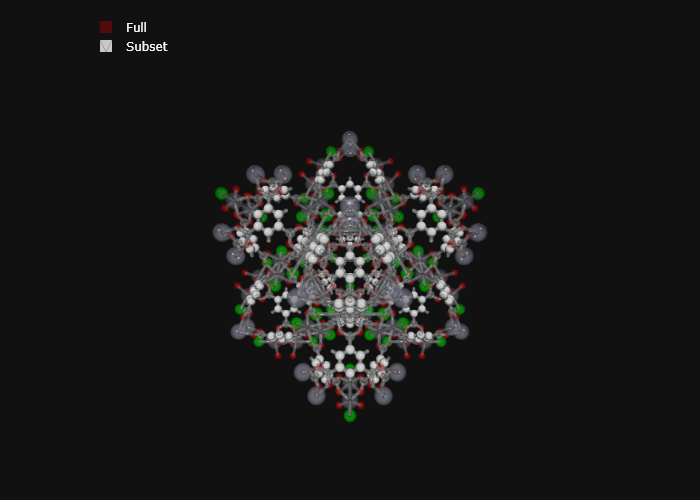

In [16]:

go.Figure([mgr.plot_mesh([mesh],stylize=True, opacity=0.3, name='Full'), mgr.plot_mesh([mesh2], stylize=True, name='Subset')], layout=mgr.dark_layout).show(renderer='png')

